In [2]:
from google.colab import auth
auth.authenticate_user()

In [69]:
import pandas as pd
import pandas_gbq
import matplotlib.pyplot as plt

Downloading: 100%|██████████|


In [ ]:
project_id = "connecticut-prison-analysis"

query = """
SELECT *
FROM `connecticut-prison-analysis.connecticut.pretrial_stays`
"""

stays = pandas_gbq.read_gbq(query, project_id=project_id)

In [4]:
len(stays)
stays.info()
stays.head()
columns_to_fix = stays.select_dtypes("dbdate").columns
for col in columns_to_fix:
  stays[col] = pd.to_datetime(stays[col])
stays.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137823 entries, 0 to 137822
Data columns (total 32 columns):
 #   Column                               Non-Null Count   Dtype 
---  ------                               --------------   ----- 
 0   identifier                           137823 non-null  object
 1   stay_id                              137823 non-null  object
 2   latest_admission_date                137823 non-null  dbdate
 3   race                                 137823 non-null  object
 4   gender                               137823 non-null  object
 5   age                                  137823 non-null  Int64 
 6   age_bucket                           137823 non-null  object
 7   facility                             137823 non-null  object
 8   fac_category                         137823 non-null  object
 9   offense                              137823 non-null  object
 10  off_category                         137823 non-null  object
 11  class                     

In [25]:
stays = stays.sort_values(["identifier", "first_seen_per_stay"])
stays.head()

stays["next_stay_start"] = stays.groupby("identifier")["first_seen_per_stay"].shift(-1)
stays["days_before_next_stay"] = (stays["next_stay_start"] - stays["last_seen_per_stay"]).dt.days.astype("Int64")
stays["days_before_next_stay"].describe()

released_per_stay = stays[stays["released_per_stay_flag"] == 1].copy()
max_date = stays["last_seen_per_stay"].max()
released_per_stay["follow_up_days"] = (max_date - released_per_stay["last_seen_per_stay"]).dt.days

released_per_stay["eligibility_30"] = released_per_stay["follow_up_days"] >= 30
released_per_stay["eligibility_90"] = released_per_stay["follow_up_days"] >= 90
released_per_stay["eligibility_365"] = released_per_stay["follow_up_days"] >= 365

released_per_stay["readmission_30"] = (released_per_stay["days_before_next_stay"].notna() & (released_per_stay["days_before_next_stay"] <= 30))
released_per_stay["readmission_90"] = (released_per_stay["days_before_next_stay"].notna() & (released_per_stay["days_before_next_stay"] <= 90))
released_per_stay["readmission_365"] = (released_per_stay["days_before_next_stay"].notna() & (released_per_stay["days_before_next_stay"] <= 365))

eligible_30 = released_per_stay[released_per_stay["eligibility_30"]].copy()
count_30 = len(eligible_30)
readmit_30 = (eligible_30["readmission_30"].mean() * 100).round(2)

eligible_90 = released_per_stay[released_per_stay["eligibility_90"]].copy()
count_90 = len(eligible_90)
readmit_90 = (eligible_90["readmission_90"].mean() * 100).round(2)

eligible_365 = released_per_stay[released_per_stay["eligibility_365"]].copy()
count_365 = len(eligible_365)
readmit_365 = (eligible_365["readmission_365"].mean() * 100).round(2)

readmission_summary = pd.DataFrame({
                      "readmit_days": [30, 90, 365],
                      "percentage" : [readmit_30, readmit_90, readmit_365],
                      "eligible_stays": [count_30, count_90, count_365]
})
readmission_summary

,identifier,stay_id,latest_admission_date,race,gender,age,age_bucket,facility,fac_category,offense,...,length_of_stay_not_released_buckets,next_stay_start,days_before_next_stay,follow_up_days,eligibility_30,eligibility_90,eligibility_365,readmission_30,readmission_90,readmission_365
112751,ZZEBBBCS,ZZEBBBCS_1,2018-08-21,White,M,47,45-54,Northern Ci,DOC Prison,"failure to appear, first degree df",...,None,2018-12-19,83,2951,True,True,True,False,True,True
113114,ZZEBBBCS,ZZEBBBCS_2,2018-12-18,White,M,47,45-54,Northern Ci,DOC Prison,"sale of heroin, coc by non-dependent",...,None,NaT,<NA>,2828,True,True,True,False,False,False
99657,ZZEBBBJW,ZZEBBBJW_1,2016-08-24,White,M,44,35-44,New Haven Cc,DOC Jail,injury or risk of injury to minor f,...,None,2017-07-07,259,3657,True,True,True,False,False,True
50811,ZZEBBBJW,ZZEBBBJW_2,2017-07-06,White,M,44,35-44,Hartford Cc,DOC Jail,crim viol of protective order am,...,None,2018-09-28,442,3392,True,True,True,False,False,False
76550,ZZEBBBJW,ZZEBBBJW_3,2018-09-27,White,M,46,45-54,Hartford Cc,DOC Jail,violation of probation or cond dischg,...,None,NaT,<NA>,2883,True,True,True,False,False,False


In [82]:
def groupby_rate(df, group_col):
  """One-year readmission rate and eligible stay count by group"""
  result = df.groupby(group_col, dropna = False).agg(yr_return_percentage = ("readmission_365", "mean"), yr_eligible_stays = ("stay_id", "count")).sort_values("yr_return_percentage", ascending = False)
  result["yr_return_percentage"] = (result["yr_return_percentage"] * 100).round(2)
  return result

display(groupby_rate(eligible_365, "off_category"))
display(groupby_rate(eligible_365, "bond_bucket"))
display(groupby_rate(eligible_365, "age_bucket"))
display(groupby_rate(eligible_365, "race"))



,yr_return_percentage,yr_eligible_stays
off_category,,
Public Order/Obstruction,41.93,8121
Court/Supervision Violation,34.47,45719
Property,33.02,15816
Drug,29.4,6555
Violent,28.23,27750
Unknown,23.38,1980
Weapons,21.58,5802
DUI/Traffic,21.08,2732
Warrant/Hold/Procedural,19.15,3938


,yr_return_percentage,yr_eligible_stays
bond_bucket,,
"$5,000-$19,999",37.78,28959
"$100-$4,999",37.19,14073
Under $100,36.51,430
"$20,000-$49,999",34.67,24321
"$50,000-$99,999",29.39,21296
"$100,000-$499,999",21.04,26211
"$500,000+",18.55,5837


,yr_return_percentage,yr_eligible_stays
age_bucket,,
Under 18,34.11,601
35-44,32.49,33254
25-34,31.72,41502
18-24,31.51,18511
45-54,28.82,17686
55+,26.27,9573


,yr_return_percentage,yr_eligible_stays
race,,
Black,31.78,44028
White,31.61,43970
Amer Ind,31.23,413
Hispanic,29.48,31870
Asian,24.11,846


In [83]:
yr_rate_by_offense_bond = (pd.pivot_table(eligible_365, values = "readmission_365",
                                          index = "off_category", columns = "bond_bucket",
                                          aggfunc = "mean") * 100).round(2)

count_by_offense_bond = pd.pivot_table(eligible_365, values = "readmission_365",
                                        index = "off_category", columns = "bond_bucket",
                                        aggfunc = "count")

bond_order = ["Under $100", "$100-$4,999", "$5,000-$19,999", "$20,000-$49,999", "$50,000-$99,999", "$100,000-$499,999", "$500,000+"]

yr_rate_by_offense_bond = yr_rate_by_offense_bond[bond_order]
count_by_offense_bond = count_by_offense_bond[bond_order]

display(yr_rate_by_offense_bond)
count_by_offense_bond

bond_bucket,Under $100,"$100-$4,999","$5,000-$19,999","$20,000-$49,999","$50,000-$99,999","$100,000-$499,999","$500,000+"
off_category,,,,,,,
Court/Supervision Violation,39.55,37.73,39.38,36.21,32.09,24.48,21.22
DUI/Traffic,23.53,22.22,21.0,23.48,18.06,17.11,23.08
Drug,35.29,35.63,38.31,31.37,26.63,19.24,18.33
Property,36.21,42.04,38.59,36.74,30.35,21.67,17.83
Public Order/Obstruction,38.6,44.55,45.41,41.35,34.08,26.83,22.95
Sexual,0.0,20.45,27.78,21.46,18.09,12.79,12.87
Unknown,<NA>,37.98,33.06,28.78,23.69,17.01,18.69
Violent,44.59,34.28,33.54,31.85,28.7,20.95,21.65
Warrant/Hold/Procedural,25.0,23.43,28.99,22.19,18.24,18.58,10.94


bond_bucket,Under $100,"$100-$4,999","$5,000-$19,999","$20,000-$49,999","$50,000-$99,999","$100,000-$499,999","$500,000+"
off_category,,,,,,,
Court/Supervision Violation,134,5521,12645,11141,8461,7195,622
DUI/Traffic,51,936,719,379,310,298,39
Drug,34,870,1527,1157,1194,1533,240
Property,58,1651,3970,3536,3031,3110,460
Public Order/Obstruction,57,2433,2852,1393,807,518,61
Sexual,5,88,234,247,376,1321,443
Unknown,<NA>,129,248,271,325,670,337
Violent,74,1975,5978,5275,5083,6912,2453
Warrant/Hold/Procedural,4,286,276,338,773,1868,393


<Axes: title={'center': 'One Year Return Rate by Offense and Bond'}, xlabel='Percentage', ylabel='Offense'>

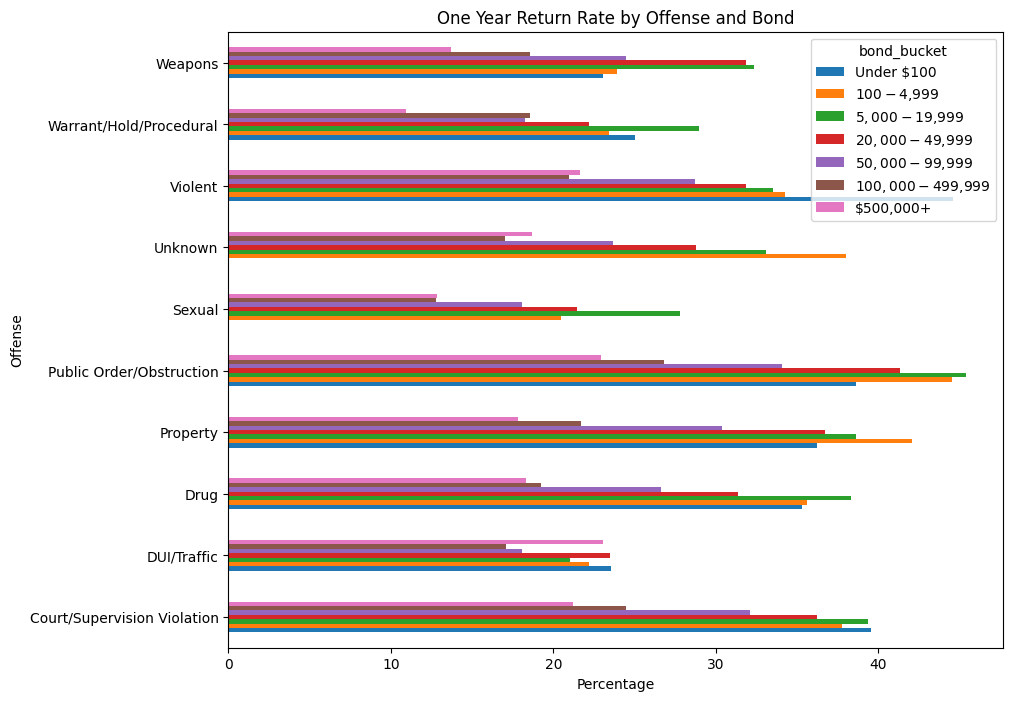

In [78]:
yr_rate_by_offense_bond.plot(kind = "barh", title = "One Year Return Rate by Offense and Bond", ylabel = "Offense", xlabel = "Percentage", figsize = (10, 8))

,stays,percent
gap_bucket,,
Within 30 days,6555,9.4
31-90 days,9917,14.3
91-180 days,10715,15.4
181-365 days,13242,19.1
Over 1 year,28943,41.7


<Axes: title={'center': 'Time Between Pretrial Release and Next Pretrial Admission'}, xlabel='Number of Stays', ylabel='Days until next admission'>

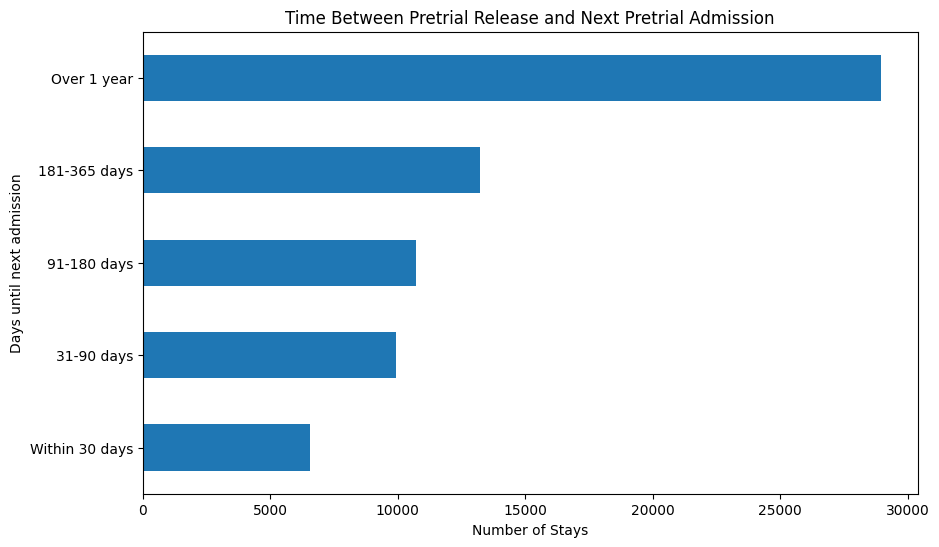

In [81]:
returned = released_per_stay[released_per_stay["days_before_next_stay"].notna()].copy()

gap_bins = [0, 30, 90, 180, 365, float("inf")]
gap_labels = ["Within 30 days", "31-90 days", "91-180 days", "181-365 days", "Over 1 year"]

returned["gap_bucket"] = pd.cut(
    returned["days_before_next_stay"].astype(float),
    bins=gap_bins,
    labels=gap_labels
)

gap_counts = returned["gap_bucket"].value_counts(sort=False)
gap_pct = (gap_counts / gap_counts.sum() * 100).round(1)

display(pd.DataFrame({"stays": gap_counts, "percent": gap_pct}))

# Plot
gap_counts.plot(kind="barh", figsize=(10, 6), title = "Time Between Pretrial Release and Next Pretrial Admission", xlabel = "Number of Stays", ylabel = "Days until next admission")